# Chapitre 9 - Cours 1 : Comprendre l'inférence, ses goulots et ses métriques

Un modèle n'est utile que s'il répond assez vite et pour un coût acceptable. Avant
d'optimiser quoi que ce soit, il faut savoir **où** le temps et l'argent partent, et
**comment** les mesurer. Ce premier notebook couvre la section *Understanding Inference
Optimization* du livre :

- *Inference Overview* : serveur et service d'inférence, API en ligne et API batch,
  streaming ;
- *Computational bottlenecks* : tâches limitées par le calcul (*compute-bound*) ou par la
  bande passante mémoire (*memory bandwidth-bound*), intensité arithmétique et modèle
  *roofline* ;
- *Inference Performance Metrics* : latence, TTFT, TPOT, percentiles, débit, coût,
  *goodput*, utilisation (MFU et MBU) ;
- *AI Accelerators* : CPU, GPU, TPU, puissance de calcul selon la précision, hiérarchie
  mémoire, consommation électrique.

Tout au long du chapitre, nous mesurons sur un vrai GPU : une **RTX 5070 Laptop** (8 Go
de mémoire GDDR7). Ce GPU est **partagé** avec d'autres travaux pendant l'exécution des
notebooks : chaque mesure est répétée, on retient la **médiane** (et parfois la meilleure
valeur), et les commentaires portent sur des **ordres de grandeur et des rapports**.

**Plan.** 1. Le service d'inférence ; 2. Deux goulots : calcul et bande passante ;
3. Prefill et decode sur le roofline ; 4. Latence : TTFT, TPOT et percentiles ; 5. Débit,
coût et goodput ; 6. Utilisation : MFU et MBU ; 7. Les accélérateurs ; Synthèse.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from aie import llm
from aie import ch09_inference as inf
from aie.ch02_modeles import KNOWN_CONFIGS, count_params_config, kv_cache_bytes, plain_log_axis
from aie.diagrams import Diagram
from aie.plotting import (set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, LIGHT,
                          annotate_bars, subtitle, finish)

set_style()
warnings.filterwarnings("ignore")
llm.seed_everything(0)
rng = np.random.default_rng(0)
pd.set_option("display.precision", 3)
RTX, H100 = inf.ACCELERATORS["RTX 5070 Laptop"], inf.ACCELERATORS["H100 SXM"]
print(torch.cuda.get_device_name(0), f"- {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} Go")

NVIDIA GeForce RTX 5070 Laptop GPU - 8.1 Go


## 1. Le service d'inférence (section *Inference Overview*)

L'entraînement **construit** un modèle ; l'inférence l'**utilise** pour calculer une sortie
(une passe avant, sans rétropropagation). En production, le composant qui exécute le
modèle s'appelle le **serveur d'inférence** : il héberge les modèles, a accès au matériel et
alloue les ressources aux requêtes. Il fait partie d'un **service d'inférence** plus large
qui reçoit, authentifie, route et prétraite les requêtes. Quand vous appelez l'API d'un
fournisseur, c'est tout ce service que vous louez ; si vous hébergez un modèle ouvert, c'est
à vous de le construire et de l'optimiser.

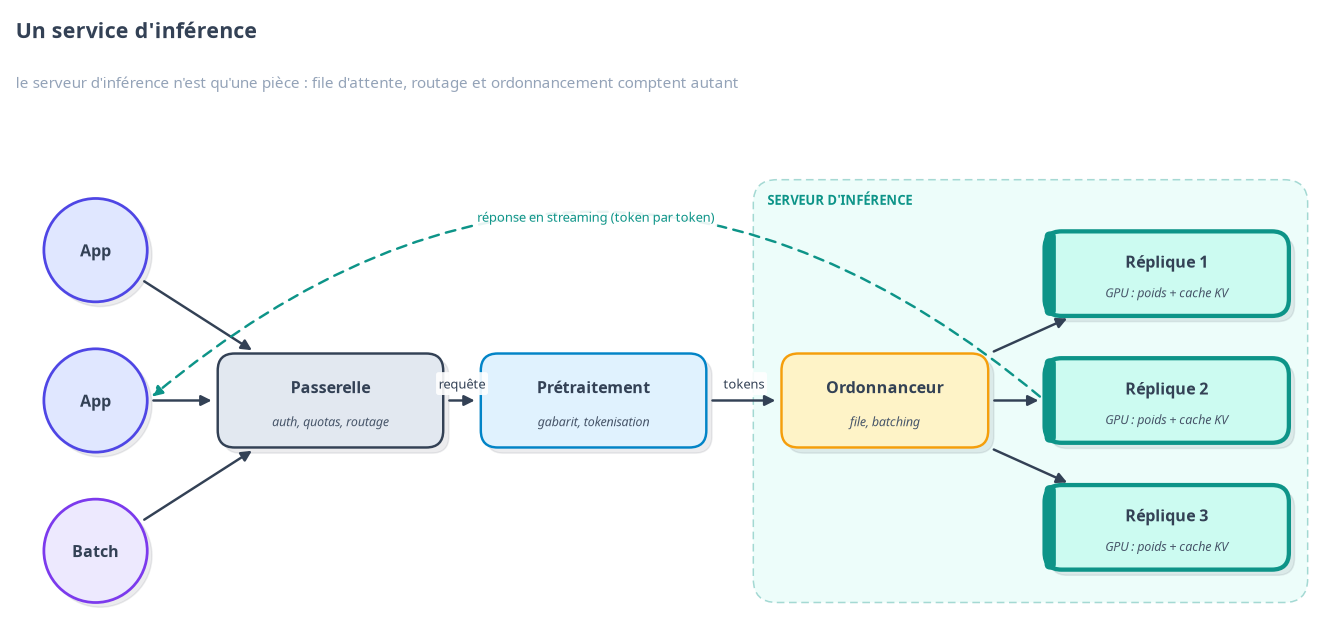

In [2]:
d = Diagram(14, 5.6, title="Un service d'inférence",
            subtitle="le serveur d'inférence n'est qu'une pièce : file d'attente, routage et ordonnancement comptent autant")
d.box("u1", 0.9, 4.0, "App", color=INDIGO, kind="user", w=1.1)
d.box("u2", 0.9, 2.4, "App", color=INDIGO, kind="user", w=1.1)
d.box("u3", 0.9, 0.8, "Batch", color=VIOLET, kind="user", w=1.1)
d.box("gw", 3.4, 2.4, "Passerelle", sub="auth, quotas, routage", color=SLATE, w=2.4, h=1.0)
d.box("pre", 6.2, 2.4, "Prétraitement", sub="gabarit, tokenisation", color=SKY, w=2.4, h=1.0)
d.group(7.9, 0.25, 13.8, 4.75, "serveur d'inférence", color=TEAL)
d.box("sch", 9.3, 2.4, "Ordonnanceur", sub="file, batching", color=AMBER, w=2.2, h=1.0)
d.box("g1", 12.3, 3.75, "Réplique 1", sub="GPU : poids + cache KV", color=TEAL, kind="model", w=2.6, h=0.9)
d.box("g2", 12.3, 2.4, "Réplique 2", sub="GPU : poids + cache KV", color=TEAL, kind="model", w=2.6, h=0.9)
d.box("g3", 12.3, 1.05, "Réplique 3", sub="GPU : poids + cache KV", color=TEAL, kind="model", w=2.6, h=0.9)
for u in ["u1", "u2", "u3"]:
    d.arrow(u, "gw")
d.arrow("gw", "pre", "requête")
d.arrow("pre", "sch", "tokens")
for g in ["g1", "g2", "g3"]:
    d.arrow("sch", g)
d.arrow("g2", "u2", "réponse en streaming (token par token)", color=TEAL, style="dashed", rad=0.42,
        label_pos=0.5, label_offset=(0, -0.05))
d.show()

**API en ligne, API batch.** Les fournisseurs proposent souvent deux modes :

- l'**API en ligne** optimise la **latence** : chaque requête est traitée dès son arrivée
  (chatbot, assistant de code) ;
- l'**API batch** optimise le **coût** : on accepte d'attendre des heures, ce qui laisse au
  fournisseur toute latitude pour regrouper les requêtes et utiliser du matériel moins cher.
  Au moment où le livre est écrit, Google et OpenAI facturent ce mode environ 50 % moins
  cher. Cas typiques : génération de données synthétiques, rapports périodiques,
  réindexation d'une base documentaire, migration vers un nouveau modèle.

Le **streaming** renvoie chaque token dès qu'il est produit : l'utilisateur voit la réponse
arriver au lieu d'attendre la fin, au prix de ne pas pouvoir filtrer la réponse complète
avant de l'afficher (chapitre 10 : garde-fous en sortie).

**Pourquoi l'inférence domine les coûts.** La note 2 du livre formalise une remarque
simple : un modèle ne se rentabilise que si les revenus de l'inférence couvrent son coût
d'entraînement $T$, soit $T \le p \cdot N$ avec $p$ le prix facturé par appel et $N$ le
nombre d'appels. Quelques ordres de grandeur :

In [3]:
T_train = 100e6  # coût d'entraînement hypothétique : 100 millions de dollars
prix_appel = np.array([0.0005, 0.002, 0.01])  # marge par appel (dollars)
appels = T_train / prix_appel
pd.DataFrame({"marge par appel ($)": prix_appel, "appels pour amortir": appels,
              "appels/jour sur 1 an": appels / 365}).style.format(
    {"marge par appel ($)": "{:.4f}", "appels pour amortir": "{:.2e}", "appels/jour sur 1 an": "{:,.0f}"})

,marge par appel ($),appels pour amortir,appels/jour sur 1 an
0,0.0005,2.00e+11,"547,945,205"
1,0.0020,5.00e+10,"136,986,301"
2,0.0100,1.00e+10,"27,397,260"


Même avec une marge d'un centime par appel, il faut des dizaines de millions d'appels par
jour pendant un an : à l'échelle d'un produit grand public, le volume d'inférence est
énorme, et chaque pourcentage gagné sur son coût compte. Selon l'étude citée par le livre
(Desislavov et al., 2023), l'inférence peut représenter jusqu'à 90 % des coûts de ML d'un
système déployé.

> **À retenir.** Serveur d'inférence = modèles + matériel + ordonnancement ; service
> d'inférence = serveur + réception, routage, prétraitement. API en ligne : on paie pour la
> latence ; API batch : on échange la latence contre un prix plus bas.

## 2. Deux goulots : calcul et bande passante (section *Computational bottlenecks*)

Optimiser, c'est d'abord trouver le goulot. Une opération sur un accélérateur fait deux
choses : **calculer** (des FLOPs, à raison de $\pi$ FLOP/s au maximum) et **déplacer des
octets** entre la mémoire et les unités de calcul (à raison de $\beta$ octets/s au
maximum). Sa durée est donc au moins
$$t \;\ge\; \max\left(\frac{\text{FLOPs}}{\pi},\; \frac{\text{octets}}{\beta}\right).$$
Le rapport des deux numérateurs est l'**intensité arithmétique**
$I = \text{FLOPs}/\text{octets}$ (opérations par octet échangé avec la mémoire). Le débit
atteignable vaut alors
$$P(I) = \min(\pi,\; I \cdot \beta) :$$
c'est le **modèle roofline** (Williams et al., 2009), nommé d'après la forme de « toit » de
sa courbe. Si $I$ est inférieure au **point d'équilibre** $I^* = \pi / \beta$, l'opération
est limitée par la **bande passante** (*memory bandwidth-bound*, souvent abrégé en
*memory-bound*) ; au-delà, elle est limitée par le **calcul** (*compute-bound*).

*Attention au vocabulaire* (encadré *Terminology Ambiguity* du livre) : certains disent
*memory-bound* pour une tâche limitée par la **capacité** mémoire (l'erreur OOM). Dans ce
chapitre, comme dans l'article *Roofline*, *memory-bound* signifie limité par la **bande
passante**.

**Intensité de quelques opérations** (en bf16, 2 octets par nombre) :

| opération | FLOPs | octets | intensité |
|---|---|---|---|
| addition de deux vecteurs de taille $n$ | $n$ | $3 \cdot 2n$ | $1/6$ |
| produit matrice-vecteur $(n \times n)\cdot(n)$ | $2n^2$ | $\approx 2n^2$ | $\approx 1$ |
| produit $(m \times k)(k \times n)$ | $2mkn$ | $2(mk + kn + mn)$ | $\approx \frac{mkn}{mk+kn+mn}$ |
| produit de matrices carrées $n \times n$ | $2n^3$ | $6n^2$ | $n/3$ |

Le produit matrice-vecteur, qui est exactement ce que fait un pas de decode avec un seul
utilisateur, n'effectue qu'**une** opération par octet lu : il sera toujours limité par la
mémoire. Le produit de grandes matrices, lui, gagne en intensité avec la taille.

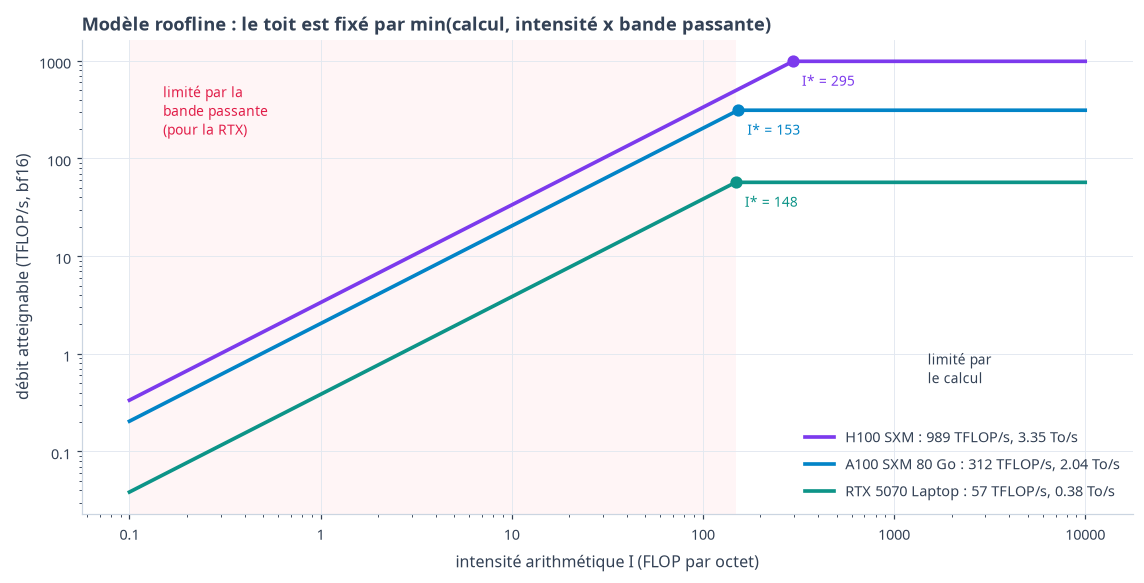

In [4]:
I = np.logspace(-1, 4, 400)
fig, ax = plt.subplots(figsize=(10.5, 5.4))
for name, a, c in [("H100 SXM", H100, VIOLET), ("A100 SXM 80 Go", inf.ACCELERATORS["A100 SXM 80 Go"], SKY),
                   ("RTX 5070 Laptop", RTX, TEAL)]:
    pi, beta = a["flops"]["bf16"], a["bw"]
    ax.plot(I, inf.roofline(I, pi, beta) / 1e12, color=c, lw=2.4, label=f"{name} : {pi / 1e12:.0f} TFLOP/s, "
            f"{beta / 1e12:.2f} To/s")
    r = inf.ridge_point(pi, beta)
    ax.plot([r], [pi / 1e12], "o", color=c, ms=7)
    ax.annotate(f"I* = {r:.0f}", (r, pi / 1e12), textcoords="offset points", xytext=(6, -16), color=c, fontsize=9)
ax.axvspan(0.1, inf.ridge_point(RTX["flops"]["bf16"], RTX["bw"]), color=LIGHT[ROSE], alpha=0.35, lw=0)
ax.text(0.15, 600, "limité par la\nbande passante\n(pour la RTX)", color=ROSE, fontsize=9, va="top")
ax.text(1500, 0.5, "limité par\nle calcul", color=SLATE, fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("intensité arithmétique I (FLOP par octet)"); ax.set_ylabel("débit atteignable (TFLOP/s, bf16)")
ax.set_title("Modèle roofline : le toit est fixé par min(calcul, intensité x bande passante)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Le point d'équilibre d'un H100 est vers 300 FLOP/octet : une opération qui fait moins de
300 opérations par octet lu laisse une partie de ses unités de calcul au chômage. Notre RTX,
17 fois moins puissante et 9 fois moins rapide en mémoire, a un point d'équilibre comparable
à celui d'un A100 (de l'ordre de 150) ; **tous** sont très au-dessus de l'intensité 1 du
produit matrice-vecteur.

**Vérifions-le sur le GPU.** On multiplie une matrice de poids $8192 \times 8192$ (bf16,
134 Mo) par un bloc de $m$ vecteurs, $m$ allant de 1 à 4096 : c'est le calcul d'une couche
linéaire pour $m$ tokens à la fois. Chaque point est la médiane (et la meilleure valeur)
de plusieurs répétitions. On mesure aussi la bande passante réellement atteinte par une
lecture de 512 Mo.

bande passante mesurée : médiane 344 Go/s, meilleure 369 Go/s (fiche : 384 Go/s)


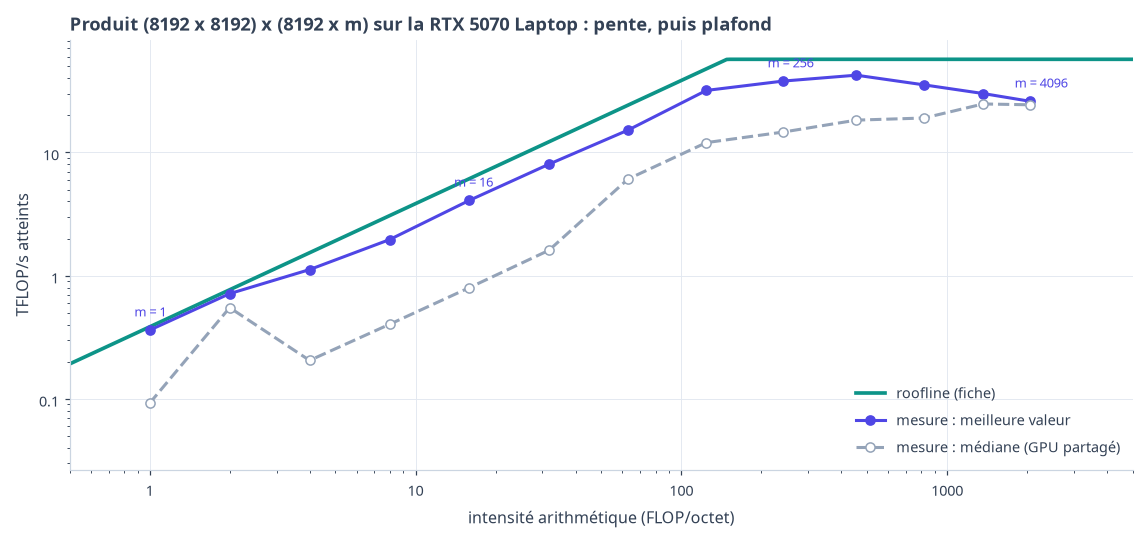

In [5]:
def bench_matmul():
    W = torch.randn(8192, 8192, device="cuda", dtype=torch.bfloat16)
    ms = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096]
    times = {m: [] for m in ms}
    for sweep in range(3):  # trois balayages entrelacés : une perturbation passagère ne touche pas tout
        for m in ms:
            X = torch.randn(8192, m, device="cuda", dtype=torch.bfloat16)
            times[m] += inf.time_fn(lambda: W @ X, repeats=8, warmup=2)["all"]
    rows = []
    for m in ms:
        f = inf.matmul_flops(8192, 8192, m)
        rows.append(dict(m=m, intensité=inf.matmul_intensity(8192, 8192, m),
                         tflops_med=f / np.median(times[m]) / 1e12, tflops_best=f / np.min(times[m]) / 1e12))
    big = torch.empty(256 * 1024 * 1024, device="cuda", dtype=torch.bfloat16)  # 512 Mo
    r = inf.time_fn(lambda: big.sum(), repeats=20, warmup=5)
    bw = dict(med=big.numel() * 2 / r["median"], best=big.numel() * 2 / r["best"])
    del W, X, big
    torch.cuda.empty_cache()
    return pd.DataFrame(rows), bw


mm, bw_meas = inf.retry_oom(bench_matmul)
print(f"bande passante mesurée : médiane {bw_meas['med'] / 1e9:.0f} Go/s, meilleure {bw_meas['best'] / 1e9:.0f} Go/s"
      f" (fiche : {RTX['bw'] / 1e9:.0f} Go/s)")

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.plot(I, inf.roofline(I, RTX["flops"]["bf16"], RTX["bw"]) / 1e12, color=TEAL, lw=2.4, label="roofline (fiche)")
ax.plot(mm["intensité"], mm["tflops_best"], "o-", color=INDIGO, label="mesure : meilleure valeur")
ax.plot(mm["intensité"], mm["tflops_med"], "o--", color=GRAY, mfc="white", label="mesure : médiane (GPU partagé)")
for _, r in mm.iloc[[0, 4, 8, 12]].iterrows():
    ax.annotate(f"m = {int(r.m)}", (r["intensité"], r.tflops_best), textcoords="offset points", xytext=(-10, 9),
                fontsize=8.5, color=INDIGO)
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlim(0.5, 5000)
ax.set_xlabel("intensité arithmétique (FLOP/octet)"); ax.set_ylabel("TFLOP/s atteints")
ax.set_title("Produit (8192 x 8192) x (8192 x m) sur la RTX 5070 Laptop : pente, puis plafond")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Les mesures épousent la forme du toit : pour $m$ petit, le débit est proportionnel à $m$
(même temps, $m$ fois plus d'opérations : on est limité par la lecture des 134 Mo de
poids) ; à partir de quelques centaines de tokens, le débit plafonne, on est limité par le
calcul. Le plafond mesuré reste sous la valeur de la fiche (une estimation pour ce portable,
dont la puissance électrique est bridée) ; quand d'autres processus utilisent le GPU, la
médiane tombe sous la meilleure valeur. Retenez les **pentes et les rapports**, pas les
valeurs absolues.

> **À retenir.** Intensité arithmétique = FLOPs / octets. Sous le point d'équilibre
> $I^* = \pi/\beta$, ajouter de la puissance de calcul ne sert à rien : il faut moins
> d'octets (quantification) ou plus de calcul par octet lu (batching).

## 3. Prefill et decode sur le roofline (section *Computational bottlenecks*)

Le chapitre 2 l'a montré : l'inférence d'un modèle autorégressif a deux phases.

- **Prefill** : les $T$ tokens du prompt traversent le réseau **en parallèle**. Chaque
  couche linéaire $d \to d'$ est un produit $(T \times d)(d \times d')$ : l'intensité croît
  avec $T$ et dépasse vite le point d'équilibre. Le prefill est *compute-bound*.
- **Decode** : un token par pas et par séquence. Avec $B$ séquences traitées ensemble, un
  pas lit $N b$ octets de poids pour $2NB$ FLOPs :
  $$I_{\text{decode}} \approx \frac{2NB}{Nb + B\,\text{KV}} \approx \frac{2B}{b},$$
  soit environ $B$ FLOP/octet en bf16 ($b = 2$) si l'on néglige la lecture du cache KV.
  Avec un seul utilisateur, $I \approx 1$ : le decode est *memory-bound*.

Plaçons ces régimes sur les deux rooflines, pour une couche MLP de Qwen2.5-1.5B
($d = 1536$, $d_{ff} = 8960$) et pour le modèle complet en decode.

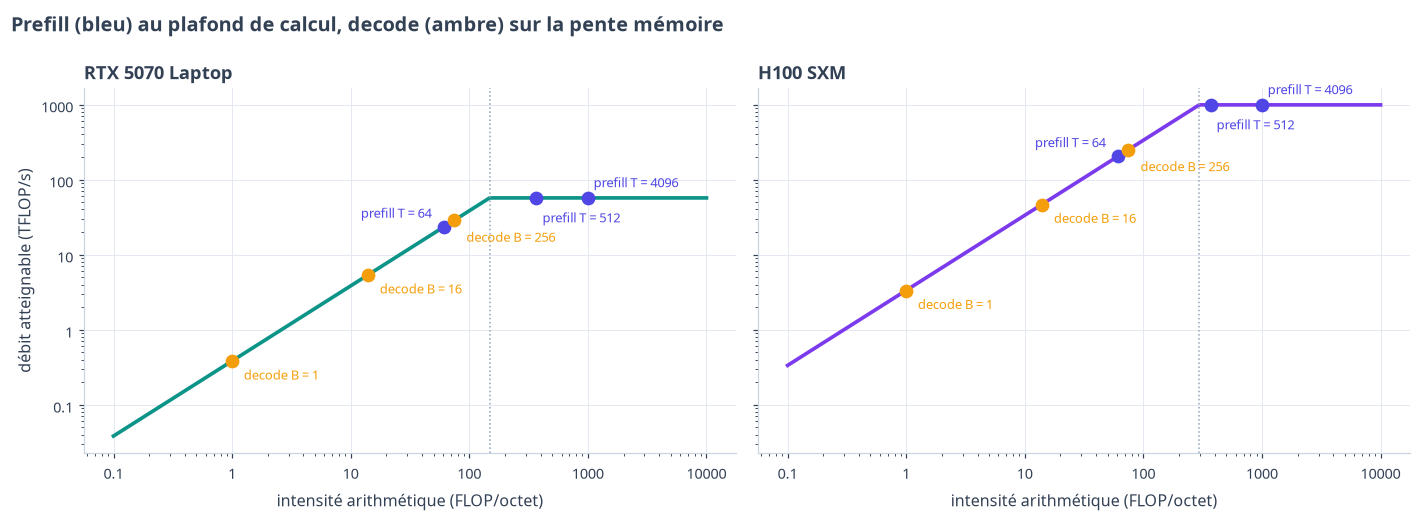

,intensité,RTX,H100
prefill T = 64,61.022,mémoire,mémoire
prefill T = 512,368.219,calcul,calcul
prefill T = 4096,993.256,calcul,calcul
decode B = 1,0.991,mémoire,mémoire
decode B = 16,13.887,mémoire,mémoire
decode B = 256,74.539,mémoire,mémoire


In [6]:
cfg15 = KNOWN_CONFIGS["Qwen2.5-1.5B"]
N15 = count_params_config(cfg15)
kv_tok = kv_cache_bytes(cfg15, 1)  # octets de cache KV par token
pts = {f"prefill T = {T}": inf.prefill_intensity(cfg15.d_model, cfg15.d_ff, T) for T in [64, 512, 4096]}
pts |= {f"decode B = {B}": inf.decode_intensity(N15, B, 2, kv_tok * 1024) for B in [1, 16, 256]}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, (name, a, c) in zip(axes, [("RTX 5070 Laptop", RTX, TEAL), ("H100 SXM", H100, VIOLET)]):
    pi, beta = a["flops"]["bf16"], a["bw"]
    ax.plot(I, inf.roofline(I, pi, beta) / 1e12, color=c, lw=2.4)
    offs = {"prefill T = 64": (-8, 6, "right"), "prefill T = 512": (4, -16, "left"),
            "prefill T = 4096": (4, 7, "left"), "decode B = 1": (8, -12, "left"),
            "decode B = 16": (8, -12, "left"), "decode B = 256": (8, -14, "left")}
    for lab, x in pts.items():
        y = float(inf.roofline(x, pi, beta)) / 1e12
        col = INDIGO if lab.startswith("prefill") else AMBER
        ax.plot([x], [y], "o", color=col, ms=8, zorder=5)
        dx, dy, ha = offs[lab]
        ax.annotate(lab, (x, y), textcoords="offset points", xytext=(dx, dy), fontsize=8.5, color=col, ha=ha)
    ax.axvline(inf.ridge_point(pi, beta), color=GRAY, ls=":", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
    ax.set_xlabel("intensité arithmétique (FLOP/octet)"); ax.set_title(name)
axes[0].set_ylabel("débit atteignable (TFLOP/s)")
finish(fig, "Prefill (bleu) au plafond de calcul, decode (ambre) sur la pente mémoire")
plt.show()
pd.DataFrame({"intensité": pts, "RTX": {k: inf.bound_kind(v, RTX["flops"]["bf16"], RTX["bw"]) for k, v in pts.items()},
              "H100": {k: inf.bound_kind(v, H100["flops"]["bf16"], H100["bw"]) for k, v in pts.items()}})

Deux enseignements. D'abord, un prefill de quelques centaines de tokens suffit pour
atteindre le plafond de calcul, alors que le decode d'un seul utilisateur exploite moins
de 1 % du calcul d'un H100. Ensuite, le **batching** fait glisser le decode vers la droite :
avec 256 séquences, l'intensité approche du point d'équilibre (sans l'atteindre ici, car
la lecture des caches KV de 1024 tokens par séquence s'ajoute à celle des poids). C'est
toute la logique du cours 4.

**Mesure sur Qwen2.5-0.5B.** Durée d'un prefill en fonction de la longueur du prompt, et
durée d'un pas de decode en fonction du nombre de séquences traitées ensemble.

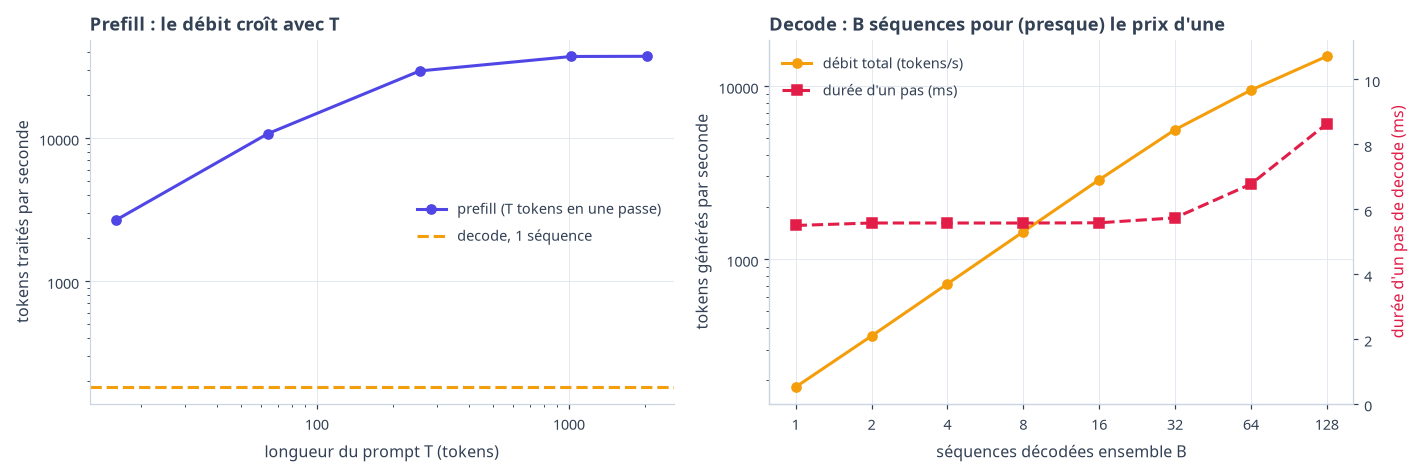

pas de decode : 5.5 ms pour B = 1, 8.6 ms pour B = 128 ; prefill de 2048 tokens : 55 ms


In [7]:
tok, model = inf.retry_oom(llm.load, llm.SMALL)
cfg05 = KNOWN_CONFIGS["Qwen2.5-0.5B"]
N05 = llm.count_params(model)


def measure_regimes():
    pre = [dict(T=T, s=inf.prefill_time(model, T, repeats=5)["median"]) for T in [16, 64, 256, 1024, 2048]]
    dec = [dict(B=B, s=inf.decode_step_time(model, batch=B, context=128, steps=16)["median"])
           for B in [1, 2, 4, 8, 16, 32, 64, 128]]
    return pd.DataFrame(pre), pd.DataFrame(dec)


pre, dec = inf.retry_oom(measure_regimes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.plot(pre["T"], pre["T"] / pre["s"], "o-", color=INDIGO, label="prefill (T tokens en une passe)")
ax.axhline(1 / dec["s"].iloc[0], color=AMBER, ls="--", label="decode, 1 séquence")
ax.set_xscale("log"); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("longueur du prompt T (tokens)"); ax.set_ylabel("tokens traités par seconde")
ax.set_title("Prefill : le débit croît avec T"); ax.legend()
ax = axes[1]
ax.plot(dec["B"], dec["B"] / dec["s"], "o-", color=AMBER, label="débit total (tokens/s)")
ax.set_xscale("log", base=2); ax.set_yscale("log"); plain_log_axis(ax, "x"); plain_log_axis(ax, "y")
ax.set_xlabel("séquences décodées ensemble B"); ax.set_ylabel("tokens générés par seconde")
ax2 = ax.twinx(); ax2.plot(dec["B"], dec["s"] * 1e3, "s--", color=ROSE, label="durée d'un pas (ms)")
ax2.set_ylabel("durée d'un pas de decode (ms)", color=ROSE); ax2.set_ylim(0, dec["s"].max() * 1e3 * 1.3)
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.set_title("Decode : B séquences pour (presque) le prix d'une")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
plt.tight_layout(); plt.show()
print(f"pas de decode : {dec['s'].iloc[0] * 1e3:.1f} ms pour B = 1, {dec['s'].iloc[-1] * 1e3:.1f} ms pour B = 128 ;"
      f" prefill de 2048 tokens : {pre['s'].iloc[-1] * 1e3:.0f} ms")

Le prefill traite des milliers de tokens par seconde, le decode d'une seule séquence
quelques dizaines à une centaine : un écart de un à deux ordres de grandeur, qui explique
pourquoi les fournisseurs facturent les tokens de sortie plusieurs fois plus cher que les
tokens d'entrée. Côté decode, la durée d'un pas reste presque constante quand $B$ passe de
1 à plusieurs dizaines : le débit total est multiplié d'autant, gratuitement. On paie
seulement quand la lecture des caches KV et le calcul finissent par compter (au-delà de
quelques dizaines de séquences pour ce petit modèle).

> **À retenir.** Prefill : intensité $\approx$ nombre de tokens du prompt, *compute-bound*,
> fixe le délai avant le premier token. Decode : intensité $\approx$ taille du lot,
> *memory-bound*, fixe la vitesse de génération. Les deux profils sont si différents qu'on
> les sépare parfois sur des machines distinctes (cours 4).